In [1]:
import os
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
dataset_path = "../dataset"
classes = os.listdir(dataset_path)

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    images = os.listdir(class_path)

    print(class_name, ":", len(images))


bacterial_leaf_blight : 1659
brown_spot : 1659
healthy : 1659
not_rice_leaf : 1658
rice_blast : 1659
tungro_disease : 1659


In [3]:
class_name = "bacterial_leaf_blight"

image_files = os.listdir(os.path.join(dataset_path, class_name))

image_path = os.path.join(dataset_path, class_name, image_files[0])

image = Image.open(image_path)

print("Image name:", image_files[0])
print("Image dimensions:", image.size)
print("Image format:", image.format)

Image name: 1.jpg
Image dimensions: (1600, 1200)
Image format: JPEG


In [4]:
dimensions = []

for file_name in image_files:
    image_path = os.path.join(dataset_path, class_name, file_name)

    image = Image.open(image_path)

    dimensions.append(image.size)

print("Total images inspected:", len(dimensions))
print("Different dimensions:", set(dimensions))

Total images inspected: 1659
Different dimensions: {(1000, 1335), (640, 428), (1600, 1600), (224, 224), (680, 912), (284, 178), (183, 275), (1600, 1200), (300, 300)}


In [5]:
dimension_counts = {}

for size in dimensions:
    if size in dimension_counts:
        dimension_counts[size] += 1
    else:
        dimension_counts[size] = 1

print(dimension_counts)

{(1600, 1200): 1, (300, 300): 343, (1600, 1600): 1265, (1000, 1335): 3, (224, 224): 31, (284, 178): 4, (680, 912): 4, (183, 275): 4, (640, 428): 4}


In [10]:
class_dimension_counts = {}
all_dimensions = []

for class_name in classes:

    folder_path = os.path.join(dataset_path, class_name)

    image_files = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    dimensions = []

    for file_name in image_files:
        image_path = os.path.join(folder_path, file_name)

        with Image.open(image_path) as image:
            dimensions.append(image.size)

    dimension_counts = {}

    for size in dimensions:
        if size in dimension_counts:
            dimension_counts[size] += 1
        else:
            dimension_counts[size] = 1

    class_dimension_counts[class_name] = dimension_counts

    # print(class_name, ":", dimension_counts)
    all_dimensions = all_dimensions + dimensions
unique_dimensions = list(set(all_dimensions))
unique_dimensions.sort(key=lambda x: x[0] * x[1])
unique_dimensions

[(224, 224),
 (186, 270),
 (259, 194),
 (275, 183),
 (183, 275),
 (253, 199),
 (200, 252),
 (271, 186),
 (285, 177),
 (284, 178),
 (318, 159),
 (225, 225),
 (278, 209),
 (210, 280),
 (280, 210),
 (211, 281),
 (281, 211),
 (212, 283),
 (283, 212),
 (284, 212),
 (283, 213),
 (213, 283),
 (284, 214),
 (214, 284),
 (286, 213),
 (214, 285),
 (285, 214),
 (214, 286),
 (286, 214),
 (215, 286),
 (286, 215),
 (215, 287),
 (287, 215),
 (216, 287),
 (287, 216),
 (288, 216),
 (216, 288),
 (216, 289),
 (289, 216),
 (250, 250),
 (289, 217),
 (217, 289),
 (219, 291),
 (291, 219),
 (292, 219),
 (219, 292),
 (293, 220),
 (220, 293),
 (220, 294),
 (294, 220),
 (220, 295),
 (295, 220),
 (295, 221),
 (221, 295),
 (296, 221),
 (221, 296),
 (222, 296),
 (296, 222),
 (223, 296),
 (296, 223),
 (223, 297),
 (297, 223),
 (298, 223),
 (223, 298),
 (297, 224),
 (224, 297),
 (299, 224),
 (224, 299),
 (300, 224),
 (224, 300),
 (225, 299),
 (299, 225),
 (300, 225),
 (301, 225),
 (225, 301),
 (227, 301),
 (301, 227),

In [12]:
original_width = 1600
original_height = 1200

target_size = 128

scale = min(
    target_size / original_width,
    target_size / original_height
)

new_width = int(original_width * scale)
new_height = int(original_height * scale)

print("Scale:", scale)
print("New width:", new_width)
print("New height:", new_height)

Scale: 0.08
New width: 128
New height: 96


In [13]:
from PIL import Image

class_name = "bacterial_leaf_blight"
image_name = "1.jpg"

image_path = os.path.join(dataset_path, class_name, image_name)

original_image = Image.open(image_path).convert("RGB")

print("Original size:", original_image.size)

Original size: (1600, 1200)


In [14]:
target_size = 128

original_width, original_height = original_image.size

scale = min(
    target_size / original_width,
    target_size / original_height
)

new_width = int(original_width * scale)
new_height = int(original_height * scale)

print("New size:", (new_width, new_height))

New size: (128, 96)


In [15]:
resized_image = original_image.resize(
    (new_width, new_height),
    Image.Resampling.LANCZOS
)

print("Resized image:", resized_image.size)

Resized image: (128, 96)


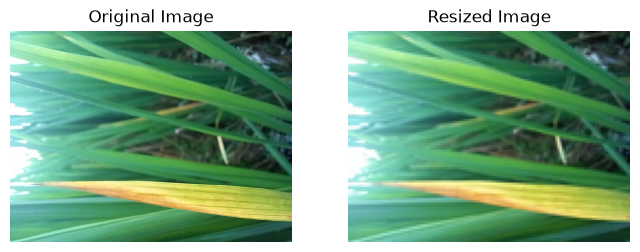

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image)
plt.title("Resized Image")
plt.axis("off")

plt.show()

In [17]:
# Create a new black background
padded_image = Image.new(
    "RGB",
    (128, 128),
    (0, 0, 0)
)

# Calculate the position to center the resized image
x_offset = (128 - new_width) // 2
y_offset = (128 - new_height) // 2

# Paste the resized image onto the background
padded_image.paste(
    resized_image,
    (x_offset, y_offset)
)

print("Final image size:", padded_image.size)

Final image size: (128, 128)


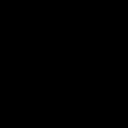

In [18]:
Image.new("RGB", (128, 128), (0, 0, 0))

In [19]:
x_offset = (128 - new_width) // 2
y_offset = (128 - new_height) // 2

In [20]:
padded_image.paste(resized_image, (x_offset, y_offset))

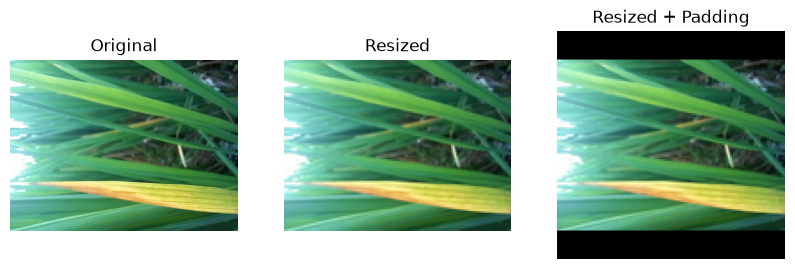

In [21]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(resized_image)
plt.title("Resized")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(padded_image)
plt.title("Resized + Padding")
plt.axis("off")

plt.show()